# The Phillips Curve and U.S. Inflation Forecasting: Recursive Autoregressive (AR) and Moving-Average (MA) Models with partial python replication of Stock and Watson (2008)





# Project Overview: Inflation Forecasting and the Phillips Curve

## 1. Macroeconomic Background

The Phillips Curve describes the short-run relationship between inflation and unemployment. In the 1950s and 1960s, economists viewed this relationship as an important guide for monetary policy. However, the **stagflation of the 1970s**, when the United States experienced high inflation alongside high unemployment, challenged the idea of a stable trade-off. The oil crises of 1973–74 and 1979 drove up energy prices, while inflation expectations contributed to persistent price and wage increases.

These developments helped motivate the **expectations-augmented Phillips Curve**, associated with economists Milton Friedman and Edmund Phelps. This framework recognizes that inflation depends partly on what households and firms expect prices to do in the future. It also highlights why inflation can remain high even as unemployment rises, making accurate inflation forecasting a persistent challenge.

## 2. Forecasting U.S. Inflation

This project compares autoregressive (AR) and moving-average (MA) models to forecast U.S. inflation using five price indexes: the GDP deflator, overall and core Personal Consumption Expenditures (PCE), and overall and core Consumer Price Index (CPI).

The models are evaluated across forecast horizons of one to twelve quarters. Using **recursive forecasting**, each model is re-estimated as new observations become available, simulating real-time forecasting conditions.

## 3. Replication: Stock and Watson (2008)

The next stage will replicate Stock and Watson's (2008) *Phillips Curve Inflation Forecasts* by translating the authors' original GAUSS code into Python. This involves reconstructing their data transformations, forecasting procedures, and evaluation methods, then comparing the results with the original study.

The aim is to understand and independently implement the underlying econometric methods, rather than simply translate code, while developing practical skills in time-series analysis and reproducible macroeconomic research.


## 1. Data Collection

We use five monthly FRED series covering inflation, unemployment, job openings, and inflation expectations.

In [61]:
!pip install fredapi
from fredapi import Fred
from google.colab import userdata
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
# Connect to FRED
fred_api_key = userdata.get("Fred_API_Key")
fred = Fred(api_key= fred_api_key)

# Pull the six FRED series
unemployment_rate = fred.get_series('UNRATE')
number_unemployed = fred.get_series('UNEMPLOY')
job_openings = fred.get_series('JTSJOL')

# I import CPI data as a percentage change from last year so it is a measure of inflation.
core_inflation = fred.get_series('CPILFESL', units = 'pc1')
headline_inflation = fred.get_series('CPIAUCSL', units = 'pc1')




In [12]:
unemployment_rate

,0
1948-01-01,3.4
1948-02-01,3.8
1948-03-01,4.0
1948-04-01,3.9
1948-05-01,3.5
...,...
2026-05-01,4.3
2026-06-01,4.2
2026-07-01,4.1
2026-08-01,4.1


The unit of observation is unemployment rate for a single month. Data is from Jan 1948 to September 2026.

In [13]:
core_inflation

,0
1957-01-01,NaN
1957-02-01,NaN
1957-03-01,NaN
1957-04-01,NaN
1957-05-01,NaN
...,...
2026-05-01,2.82294
2026-06-01,2.56579
2026-07-01,2.46652
2026-08-01,2.44616


- The unit of observation is the inflation rate for a specific month. Inflation is calculated as the percentage change in the CPI level from the same month one year earlier. We use core inflation only as food and energy prices are very volatile.

- The first 12 observations return NaN because the dataset begins in January 1957 and there is no CPI observation from the previous year. Therefore, the calculated inflation series begins in January 1958 and extends through August 2026.

- The CPI uses 1982–1984 as its base period, with an index value of 100. However, this base does not affect the calculated inflation rate because inflation is based on the percentage change in CPI over the previous 12 months. For example, an inflation rate of 2.44616% in August 2026 means that the CPI was 2.44616% higher than in August 2025.


In [14]:
number_unemployed

,0
1948-01-01,2034.0
1948-02-01,2328.0
1948-03-01,2399.0
1948-04-01,2386.0
1948-05-01,2118.0
...,...
2026-05-01,7307.0
2026-06-01,7094.0
2026-07-01,6916.0
2026-08-01,7031.0


The unit of observation is the unemployment level for a specific month. It measures the aggregate number of people currently unemployed in the U.S., reported in thousands of persons. For example, a value of 7,109 in September 2026 represents 7,109,000 unemployed people in the U.S. in that month. Data is from January 1948 to September 2026.


In [15]:
job_openings

,0
2000-12-01,5088.0
2001-01-01,5234.0
2001-02-01,5097.0
2001-03-01,4762.0
2001-04-01,4615.0
...,...
2026-04-01,7585.0
2026-05-01,7537.0
2026-06-01,7182.0
2026-07-01,7335.0


The unit of observation are the number of job openings for a specific month. Data is from December 2000 to August 2026. The level is in thousands, so 7,079 in August 2026 means there were 7,079,000 job openings in the US in that month.




## 2. Combining the Data

Each FRED series is returned separately, so we combine the five series into one DataFrame using their monthly dates.

In [16]:
# Combine all six series using their dates. Renamed as intial series had no names.
df = pd.concat([unemployment_rate.rename("unemployment_rate"),
                core_inflation.rename("core_inflation"),
                number_unemployed.rename("number_unemployed"),
                job_openings.rename("job_openings"),
               headline_inflation.rename("headline_inflation")],
               axis =1)


### Quick Look at the Data

In [17]:
# View the first few observations
df.head()

,unemployment_rate,core_inflation,number_unemployed,job_openings,headline_inflation
1947-01-01,NaN,NaN,NaN,NaN,NaN
1947-02-01,NaN,NaN,NaN,NaN,NaN
1947-03-01,NaN,NaN,NaN,NaN,NaN
1947-04-01,NaN,NaN,NaN,NaN,NaN
1947-05-01,NaN,NaN,NaN,NaN,NaN


In [18]:
# View the last few observations
df.tail()

,unemployment_rate,core_inflation,number_unemployed,job_openings,headline_inflation
2026-05-01,4.3,2.82294,7307.0,7537.0,4.16661
2026-06-01,4.2,2.56579,7094.0,7182.0,3.46353
2026-07-01,4.1,2.46652,6916.0,7335.0,3.30386
2026-08-01,4.1,2.44616,7031.0,7079.0,3.35302
2026-09-01,4.2,2.56584,7109.0,NaN,3.71725


* Initial missing values because expected_inflation observations start in January 1982, core_inflation in January 1958, and job_openings in December 2000.

* Mising observations in September 2026 as core_inflation and job_openings observations end in August 2026.







## 3. Preliminary Data Check

We now check the size, structure, and completeness of the combined dataset.

In [19]:
# Check the number of rows and columns
df.shape

(957, 5)

We have 945 monthly observations and 5 columns.

### Column Names and Data Types

In [20]:
# Check column names, data types, and non-missing values
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 957 entries, 1947-01-01 to 2026-09-01
Freq: MS
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   unemployment_rate   944 non-null    float64
 1   core_inflation      824 non-null    float64
 2   number_unemployed   944 non-null    float64
 3   job_openings        309 non-null    float64
 4   headline_inflation  944 non-null    float64
dtypes: float64(5)
memory usage: 44.9 KB


All columns follow the float64 datatype, which is expected as they are rates and values of economic indicators.

### Missing Values

We check for missing observations before choosing our analysis period.

In [21]:
# Count missing values in each column
df.isna().sum()

,0
unemployment_rate,13
core_inflation,133
number_unemployed,13
job_openings,648
headline_inflation,13


The series do not all cover the same time period. This is because unemployment_rate begins in January 1948, expected_inflation in January 1982, core_inflation in January 1958, number_unemployed in January 1948, and job_openings in December 2000.  We will handle missing values according to the needs of our specific visualizations.

### Summary Statistics

We use basic summary statistics to understand the range and typical values of each variable.

In [22]:
# Summary statistics for the numerical variables
df.describe()

,unemployment_rate,core_inflation,number_unemployed,job_openings,headline_inflation
count,944.000000,824.000000,944.000000,309.000000,944.000000
mean,5.652966,3.654169,6611.273305,5515.174757,3.519230
std,1.703534,2.457797,3012.011721,2270.648485,2.858915
min,2.500000,0.602720,1596.000000,2232.000000,-2.988130
25%,4.300000,2.015273,4073.500000,3774.000000,1.670848
50%,5.450000,2.774150,6653.000000,4747.000000,2.867950
75%,6.700000,4.609595,8167.750000,7066.000000,4.415015
max,14.800000,13.604490,23084.000000,12301.000000,14.592270


The maximum unemployment_rate, maximum core_inflation, and maximum number_unemployed likely all happened during specific economic crises, which we will study under the visualizations. Since we will divide our dataset into eras, we will not drop the outliers as they inform our analysis and show the impact of economic events.

## 4. Creating the Analysis Variables

We now create a measure of labor-market tightness using job openings per unemployed person.  

### Labor-Market Tightness

We calculate job openings per unemployed person (V/U) as a measure of labor-market tightness. It measures for each unemployed person, the number of job openings available.

In [23]:
# Calculate job openings per unemployed person
df["vu"] = df["job_openings"] / df["number_unemployed"]

# Since job_openings starts in December 2000, we take a look at the data beginning December 2000.
df.loc['2000-12-01': ,["job_openings", "number_unemployed", "vu"]].head()

,job_openings,number_unemployed,vu
2000-12-01,5088.0,5634.0,0.903088
2001-01-01,5234.0,6023.0,0.869002
2001-02-01,5097.0,6089.0,0.837083
2001-03-01,4762.0,6141.0,0.775444
2001-04-01,4615.0,6271.0,0.735927


### Tight and Slack Labor Markets

We classify months with more than one job opening per unemployed person as tight and the remaining months as slack.

In [24]:
df["market_status"] = np.where(df["vu"] > 1, "tight", "slack")
df.loc['2000-12-01':, "market_status"].value_counts()

,count
market_status,
slack,232
tight,78


In [25]:
df

,unemployment_rate,core_inflation,number_unemployed,job_openings,headline_inflation,vu,market_status
1947-01-01,NaN,NaN,NaN,NaN,NaN,NaN,slack
1947-02-01,NaN,NaN,NaN,NaN,NaN,NaN,slack
1947-03-01,NaN,NaN,NaN,NaN,NaN,NaN,slack
1947-04-01,NaN,NaN,NaN,NaN,NaN,NaN,slack
1947-05-01,NaN,NaN,NaN,NaN,NaN,NaN,slack
...,...,...,...,...,...,...,...
2026-05-01,4.3,2.82294,7307.0,7537.0,4.16661,1.031477,tight
2026-06-01,4.2,2.56579,7094.0,7182.0,3.46353,1.012405,tight
2026-07-01,4.1,2.46652,6916.0,7335.0,3.30386,1.060584,tight
2026-08-01,4.1,2.44616,7031.0,7079.0,3.35302,1.006827,tight


## 5. Visualization 1 - The traditional Phillips Curve relation (1958 -2026)


In this visualization, we plot unemployment_rate against core_inflation to check if there appears to be an inverse relation. We are not claiming any causal relation. We are just searching for a pattern.

Since we have core_inflation observations starting from January 1958, we begin our visualization from that point. This helps us have a wider span of data to look over, instead of being limited by the observations of job_openings.

In [26]:
# Core Inflation observations are from January 1958 to August 2026 so we restrict the dataset for analysis.
df_1 = df.loc['1958-01-01': '2026-08-01', ['core_inflation', 'unemployment_rate']]
df_1

,core_inflation,unemployment_rate
1958-01-01,2.80702,5.8
1958-02-01,2.79720,6.4
1958-03-01,2.78746,6.7
1958-04-01,2.43056,7.4
1958-05-01,2.43056,7.4
...,...,...
2026-04-01,2.74331,4.3
2026-05-01,2.82294,4.3
2026-06-01,2.56579,4.2
2026-07-01,2.46652,4.1


In [27]:
# Checking for null values
df_1.isna().sum()

,0
core_inflation,1
unemployment_rate,1


In [28]:
# The missing value exists because of a 43 day federal government shutdown in October 2025
df_1[df_1.isna().any(axis =1)]

,core_inflation,unemployment_rate
2025-10-01,NaN,NaN


In [29]:
# We drop the missing value
df_1 = df_1.dropna()
# Updated Shape and Info
print(df_1.shape)
print(df_1.info())

(823, 2)
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 823 entries, 1958-01-01 to 2026-08-01
Data columns (total 2 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   core_inflation     823 non-null    float64
 1   unemployment_rate  823 non-null    float64
dtypes: float64(2)
memory usage: 19.3 KB
None


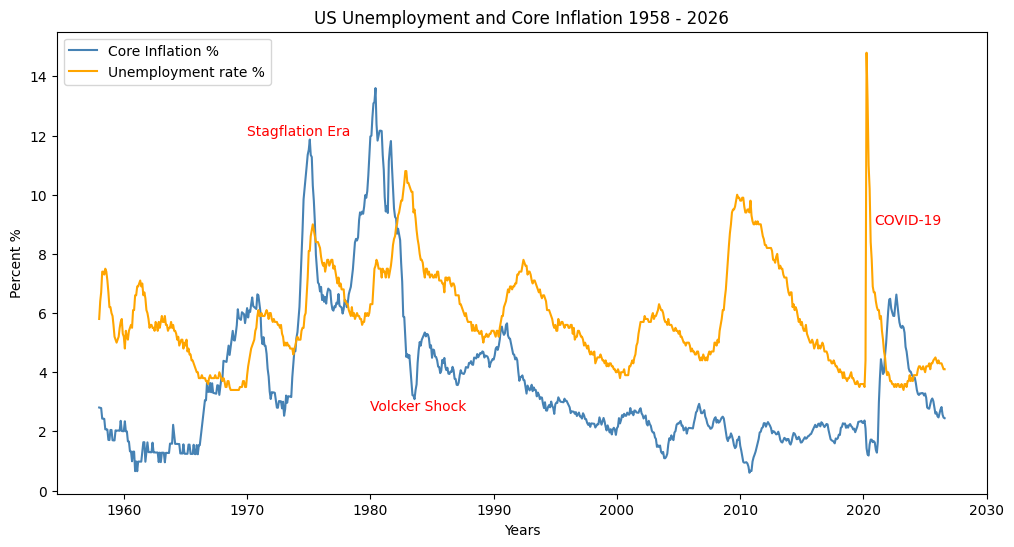

In [30]:
fig,ax = plt.subplots(figsize =(12,6))
ax.plot(df_1.index, df_1["core_inflation"], color = "steelblue", label = "Core Inflation %")
ax.plot(df_1.index, df_1["unemployment_rate"], color = "orange", label = "Unemployment rate %")
ax.set_xlabel("Years")
ax.set_ylabel("Percent %")
ax.set_title("US Unemployment and Core Inflation 1958 - 2026")
ax.legend(loc = 'upper left')
ax.text(pd.to_datetime("1970-01-01"), 12, "Stagflation Era", color="red")
ax.text(pd.to_datetime("1980-01-01"), 2.7, "Volcker Shock", color="red")
ax.text(pd.to_datetime("2020-11-01"),9, "COVID-19", color="red");

* In the 1960s, we see that as core inflation remains low, unemployment is generally higher, which is in line with the inverse relation under Phillips curve.
* In the mid 1970s, both unemployment and inflation increase drastically, so there is no inverse relation. This is the stagflation (high unemployment, high inflation) era.
* In the 1980s, Chairman of Federal Reserve Paul Volcker in his 'war on inflation' massively restricted bank reserves to constrain demand and reduce inflation, which is why inflation falls from nearly 14% to around 3% in 1983.
* This leads to the period of 'Great Moderation' where the inflation remains somewhat stable. COVID-19 skyrockets the unemployment rate as firms cut workforces amidst the pandemic.



## 6. Visualization 2 - Expectations-Augmented Phillips Curve (1970 - 2026)

* When the traditional Phillips curve relation broke down in the 1970s,   macroeconomists believed it was due to de-anchoring of expectations. Before in the 1960s, people expected the inflation to be fixed. Because of oil crises and global economic changes, now people in the US did not believe that the Fed could keep prices stable, so they expected high prices to be persistent.

* Inflation in one year was equal to inflation in the previous year as high prices were expected.

* We test this relationship from 1970 to 2026.


In [31]:
# Restricting the dataset for analysis. We start at 1969 so we can get a value for 1970 as seen down below.
df_2 = df.loc["1969-01-01" : "2026-08-01", ["headline_inflation", "unemployment_rate"]]

In [32]:
# We groupby years to get the average inflation each year.
df_2 = df_2.groupby(df_2.index.year).agg(
    headline_inflation_yearly = ("headline_inflation", "mean"),
    unemployment_yearly = ("unemployment_rate", "mean"))

In [33]:
# Now we calculate the inflation gap, which is inflation minus inflation in the previous year.
df_2["headline_inflation_yearly_1m"] = df_2["headline_inflation_yearly"].shift(1)
df_2["inflation_gap"] = df_2["headline_inflation_yearly"] - df_2["headline_inflation_yearly_1m"]


In [34]:
# Checking for null values
df_2.isna().sum()

,0
headline_inflation_yearly,0
unemployment_yearly,0
headline_inflation_yearly_1m,1
inflation_gap,1


In [35]:
# Since we have no observation for 1968, we lose the observations for 1969. Hence, we drop null values
df_2 = df_2.dropna()
# Updated Shape and Info
print(df_2.shape)
print(df_2.info())

(57, 4)
<class 'pandas.core.frame.DataFrame'>
Index: 57 entries, 1970 to 2026
Data columns (total 4 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   headline_inflation_yearly     57 non-null     float64
 1   unemployment_yearly           57 non-null     float64
 2   headline_inflation_yearly_1m  57 non-null     float64
 3   inflation_gap                 57 non-null     float64
dtypes: float64(4)
memory usage: 2.0 KB
None


In [36]:
# We introduce different eras to understand the shape of the Phillips Curve
df_2 = df_2.copy()
df_2["era"] = ""
df_2.loc[1970:1983, "era"] = "1970-1983 (Accelerationist)"
df_2.loc[1984:2007, "era"] = "1984-2007 (Great Moderation)"
df_2.loc[2008:2026, "era"] = "2008-2026 (Contemporary)"

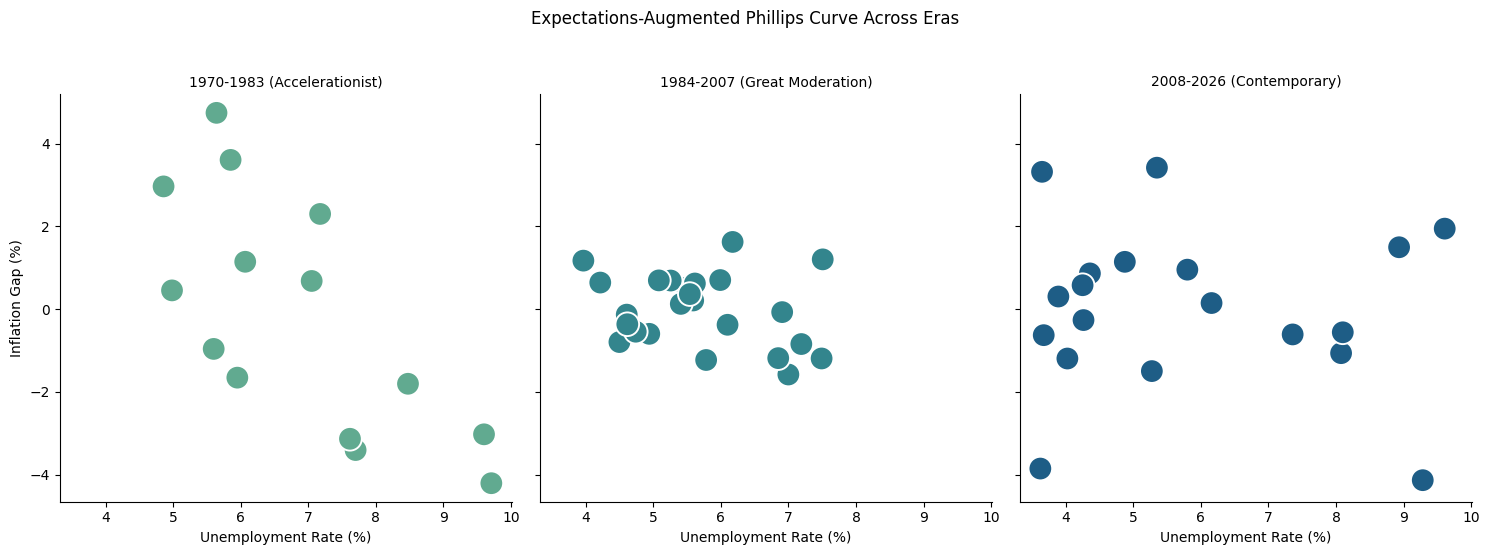

In [37]:
v2 = sns.relplot(data = df_2, x = "unemployment_yearly", y = "inflation_gap", col = "era", kind = "scatter", hue = "era", legend = False,
                 palette = "crest", s = 290)
v2.set_xlabels("Unemployment Rate (%)")
v2.set_ylabels("Inflation Gap (%)")
v2.set_titles(col_template="{col_name}")
v2.fig.suptitle("Expectations-Augmented Phillips Curve Across Eras", y = 1.1);


* In the 1970s, the expectations-augmented Phillips Curve follows an inverse relation. After we adjusted for inflation expectations (as people expected them to be based on previous year), we see an inverse relation like the traditional Phillips Curve.

* In the Great Moderation era, inflation expectations had become anchored i.e stable after the tight policies of Paul Volcker.

* In the modern times, the Great Recession and COVID led to spikes in inflation/deflation and unemployment. Largely, inflation expectations remained contained.

## Visualization 3 - Vacancies-based Phillips Curve

We now use an alternative measure of labor market conditions to examine the relationship between inflation and labor market slack. The unemployment rate captures only the supply side of the labor market (the number of people looking for work). Instead, we use job openings (vacancies) per unemployed person (V/U). This also incorporates the demand side (firms’ hiring needs), giving a fuller picture of overall labor market tightness.

In [38]:
# Since we only have job openings data from Dec 2000, we restrict the dataset.
df_3 = df.loc["2000-12-01":"2026-08-01", ["unemployment_rate", "core_inflation", "vu"]]

In [39]:
# We first create bin boundaries
bins = [0, 0.5, 0.75, 1, 1.25, 1.5, 2, 3]
labels = ["<0.5", "0.5-0.75", "0.75-1", "1-1.25", "1.25-1.5", "1.5-2", ">2"]

# Now we add the bucket column
df_3["vu_bucket"] = pd.cut(df_3["vu"], bins = bins, labels =labels)

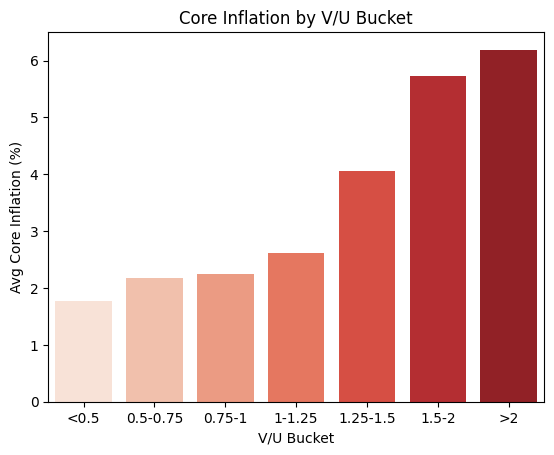

In [40]:
bucket_avg = (df_3.groupby("vu_bucket", observed=False)["core_inflation"].mean().reset_index())

ax = sns.barplot(data=bucket_avg, x="vu_bucket", y="core_inflation", hue="vu_bucket", palette="Reds", legend=False)
plt.xlabel("V/U Bucket")
plt.ylabel("Avg Core Inflation (%)")
plt.title("Core Inflation by V/U Bucket");
plt.show()

The figure shows average core inflation (12-month change in core CPI) for months grouped by labor-market tightness, measured as job openings per unemployed person (V/U). Average inflation rises steadily as V/U rises. Months with fewer than 0.5 openings per unemployed person (very slack labor markets) average roughly 1.8% core inflation. Months with 1.5 to 2 openings per unemployed person, and above 2, average roughly 5.7% and 6.2%. The relationship is mild when V/U is below about 1.25 and steepens sharply above it. This is consistent with a nonlinear Phillips curve: when labor markets are slack, tightening has little effect on inflation, but once vacancies exceed the number of job seekers, inflation rises much faster.

# Replicating Stock and Watson (2008): Inflation Forecasting

This project replicates selected inflation forecasting models from Stock and Watson (2008) using Python. The analysis compares forecasts generated by recursive autoregressive (AR) models and moving-average (MA) models across five U.S. inflation measures.

The objective is to understand how these forecasting models are implemented, evaluate their out-of-sample forecasting performance across different forecast horizons, and develop practical skills in macroeconometric research through replication.

## 1. Data Preparation

The dataset is provided in the `Bfed.xls` workbook, which contains separate monthly and quarterly data sheets. The monthly sheet supplies the overall and core Consumer Price Index (CPI) series, while the quarterly sheet supplies the GDP price index, overall Personal Consumption Expenditures (PCE) price index, and core PCE price index.

This section loads both sheets, standardizes column names, converts the date columns to datetime format, removes observations with invalid dates, and sets the date as the index. The monthly data are restricted to the sample period from January 1947 through April 2008. The resulting datasets are then inspected before constructing the five quarterly inflation measures used in the forecasting analysis.

### Before running: download the data

This section needs the original dataset from Stock and Watson (2008), which is not included in this repository. To run it:

1. Download the replication files for *Phillips Curve Inflation Forecasts* (Stock and Watson, 2008) from Mark Watson's website at Princeton University. The file you need is **`Bfed.xls`**.
2. In your Google Drive, create a folder named **`Stock_Watson_Replication`** (inside "My Drive").
3. Upload `Bfed.xls` into that folder, so the full path is:
   `My Drive/Stock_Watson_Replication/Bfed.xls`
4. Run the cell below. Google Colab will ask you to authorize access to your Drive.

If you save the file somewhere else, update the `file_path` variable in the cell below to match.

*This notebook is written for Google Colab. To run it locally instead, remove the `google.colab` and `drive.mount` lines and set `file_path` to wherever you saved the file on your computer.*

In [41]:
import pandas as pd
import numpy as np
from google.colab import drive

drive.mount('/content/drive')

%pip install xlrd

file_path = '/content/drive/MyDrive/Stock_Watson_Replication/Bfed.xls'

monthly = pd.read_excel(file_path, sheet_name="Monthly")
quarterly = pd.read_excel(file_path, sheet_name="Quarterly")

# Clean column names and dates
for df in [monthly, quarterly]:
    df.columns = df.columns.str.strip().str.upper()
    df["DATE"] = pd.to_datetime(df["DATE"], errors="coerce")
    df.dropna(subset=["DATE"], inplace=True)

# Restrict the monthly sample and set date indexes
monthly = monthly.loc[
    monthly["DATE"].between("1947-01-01", "2008-04-30")
].set_index("DATE").sort_index()

quarterly = quarterly.set_index("DATE").sort_index()

print("Monthly data:", monthly.shape)
print("Quarterly data:", quarterly.shape)

display(monthly.head())
display(quarterly.head())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Monthly data: (736, 21)
Quarterly data: (245, 7)


,AHETPI,AWHI,CLF16OV,CPIAUCSL,CPILFESL,INDPRO,PAYEMS,PCEPI,PCEPILFE,PERMIT,...,TWEXMMTH,UEMPLT5,UNRATE,CFNAI,CPI_M_1,CPI_M_2,CPI_TM_1,CPI_TM_2,FYGM3,FYGT1
DATE,,,,,,,,,,,,,,,,,,,,,
1947-01-01,NaN,NaN,NaN,21.5,NaN,15.2713,43545,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.38,NaN
1947-02-01,NaN,NaN,NaN,21.6,NaN,15.3615,43563,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.38,NaN
1947-03-01,NaN,NaN,NaN,22.0,NaN,15.4517,43605,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.38,NaN
1947-04-01,NaN,NaN,NaN,22.0,NaN,15.3315,43491,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.38,NaN
1947-05-01,NaN,NaN,NaN,22.0,NaN,15.3916,43637,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.38,NaN


,GDPC96,GDPCTPI,GDPDEF,JCXFE,PCECTPI,PRS85006173,B021RG3
DATE,,,,,,,
1947-01-01,1570.519,15.115,15.105,NaN,15.366,106.181,16.298
1947-04-01,1568.653,15.335,15.329,NaN,15.491,103.963,17.455
1947-07-01,1567.966,15.590,15.597,NaN,15.777,104.642,18.396
1947-10-01,1590.938,15.912,15.989,NaN,16.174,103.417,19.018
1948-01-01,1616.069,16.093,16.111,NaN,16.356,103.668,19.461


## 2. Constructing the Quarterly Dataset

The forecasting analysis uses five U.S. price indexes: the GDP price index, the overall and core PCE price indexes, and the overall and core CPI indexes.

The CPI series are provided at monthly frequency, so they are converted to quarterly frequency by taking the average of the monthly observations within each quarter. The remaining three price indexes are already quarterly. The datasets are then combined by date to create a single dataset containing all five measures.

In [42]:
# Convert monthly CPI indexes to quarterly averages
quarterly_from_monthly = monthly[
    ["CPIAUCSL", "CPILFESL"]
].rename(columns={
    "CPIAUCSL": "p_cpi_all",
    "CPILFESL": "p_cpi_lfe"
}).resample("QS").mean()

quarterly_from_monthly = quarterly_from_monthly.loc[:"2008-01-01"]

# Select the quarterly GDP and PCE price indexes
qvars = quarterly[
    ["GDPCTPI", "PCECTPI", "JCXFE"]
].rename(columns={
    "GDPCTPI": "p_gdp",
    "PCECTPI": "p_pce_all",
    "JCXFE": "p_pce_lfe"
})

# Combine all five price indexes
data = quarterly_from_monthly.join(qvars, how="left")

print("Forecasting data:", data.shape)
display(data.head())
display(data.tail())

Forecasting data: (245, 5)


,p_cpi_all,p_cpi_lfe,p_gdp,p_pce_all,p_pce_lfe
DATE,,,,,
1947-01-01,21.700000,NaN,15.115,15.366,NaN
1947-04-01,22.033333,NaN,15.335,15.491,NaN
1947-07-01,22.466667,NaN,15.590,15.777,NaN
1947-10-01,23.133333,NaN,15.912,16.174,NaN
1948-01-01,23.633333,NaN,16.093,16.356,NaN


,p_cpi_all,p_cpi_lfe,p_gdp,p_pce_all,p_pce_lfe
DATE,,,,,
2007-01-01,204.269333,208.975333,118.750,116.129,113.730
2007-04-01,206.565667,210.024667,119.527,117.345,114.116
2007-07-01,207.988667,211.309333,119.837,117.873,114.682
2007-10-01,210.555000,212.614667,120.560,119.019,115.403
2008-01-01,212.796000,213.930667,121.337,120.052,116.019


## 3. Forecasting Parameters and Variable Construction

This section defines the parameters for the recursive forecasting exercise. The minimum estimation sample is 40 complete observations, and the maximum forecast horizon is twelve quarters. Six columns are constructed for the change in inflation and its lags, while the forecasting sample begins in 1953 Q1.

For each of the five price indexes, the code calculates the log price level, quarterly inflation, and the change in inflation. It then constructs the current change in inflation and its five lags, scaling these variables by 400 to express quarterly changes at an annualized percentage rate. The resulting transformed data are stored in `forecast_data` for use in the forecasting models.

In [43]:
# Parameters from the original GAUSS program
npmin = 40
hmax = 12
narmax_ddp = 6
first_obs = pd.Timestamp("1953-01-01")

# Five price measures, in the same order as the GAUSS program
inflation_measures = [
    "p_gdp",
    "p_pce_all",
    "p_pce_lfe",
    "p_cpi_all",
    "p_cpi_lfe",
]

# Store the constructed variables and forecasts
forecast_data = {}
ar1_recursive = {}

# Construct variables separately for each price measure
for measure in inflation_measures:

    # Log price index and inflation transformations
    p = np.log(data[measure])
    dp = p.diff()
    ddp = dp.diff()

    # Construct the lag matrix before restricting the sample
    variables = pd.DataFrame({
        "p": p,
        "dp": dp,
        "ddp": ddp,
    }, index=data.index)

    lag_columns = []

    for lag in range(narmax_ddp):
        column = f"ddp_lag{lag}"
        variables[column] = ddp.shift(lag)
        lag_columns.append(column)

    # Select observations from 1953 Q1 onward
    sample = variables.loc[variables.index >= first_obs].copy()

    # Scale all six lag columns as in GAUSS
    sample[lag_columns] = 400 * sample[lag_columns]

    forecast_data[measure] = sample

    # Recursive AR(1) forecasts for horizons 1 through 12 quarters
    for h in range(1, hmax + 1):

        # Future h-quarter log price change, aligned to the forecast origin
        future_log_change = sample["p"].shift(-h) - sample["p"]

        # Dependent variable and known component, matching GAUSS
        yh = (400 / h) * (
            future_log_change - h * sample["dp"]
        )

        yh1 = (400 / h) * future_log_change
        yh2 = (400 / h) * (-h * sample["dp"])

        forecasts = np.full(len(sample), np.nan)

        # Use a 1-based t below to match the GAUSS indexing
        for t in range(h + 1, len(sample) + 1):

            # GAUSS estimates using outcomes known by forecast origin t
            train_end = t - h

            training = pd.concat(
                [
                    yh.rename("yh"),
                    sample[lag_columns],
                ],
                axis=1,
            ).iloc[:train_end].dropna()

            # Require at least 40 complete observations
            if len(training) < npmin:
                continue

            # AR(1): constant plus the first ddp regressor
            X_train = np.column_stack([
                np.ones(len(training)),
                training["ddp_lag0"].to_numpy(),
            ])
            y_train = training["yh"].to_numpy()

            # Ordinary least squares, equivalent to the GAUSS regression
            beta = np.linalg.lstsq(X_train, y_train, rcond=None)[0]

            # Forecast at the current origin using its known ddp value
            current_ddp = sample["ddp_lag0"].iloc[t - 1]

            if pd.isna(current_ddp):
                continue

            predicted_yh = np.array([1.0, current_ddp]) @ beta

            # Add back the known inflation component
            forecasts[t - 1] = predicted_yh - yh2.iloc[t - 1]

        # Save actual future inflation and the forecast
        ar1_recursive[(measure, h)] = pd.DataFrame(
            {
                "actual": yh1,
                "forecast": forecasts,
            },
            index=sample.index,
        )



## 4. Evaluating Recursive AR(1) Forecasts

This section plots actual GDP price inflation against the recursive AR(1) forecasts for the one-quarter-ahead horizon. Observations with missing actual values or forecasts are excluded from the plot.

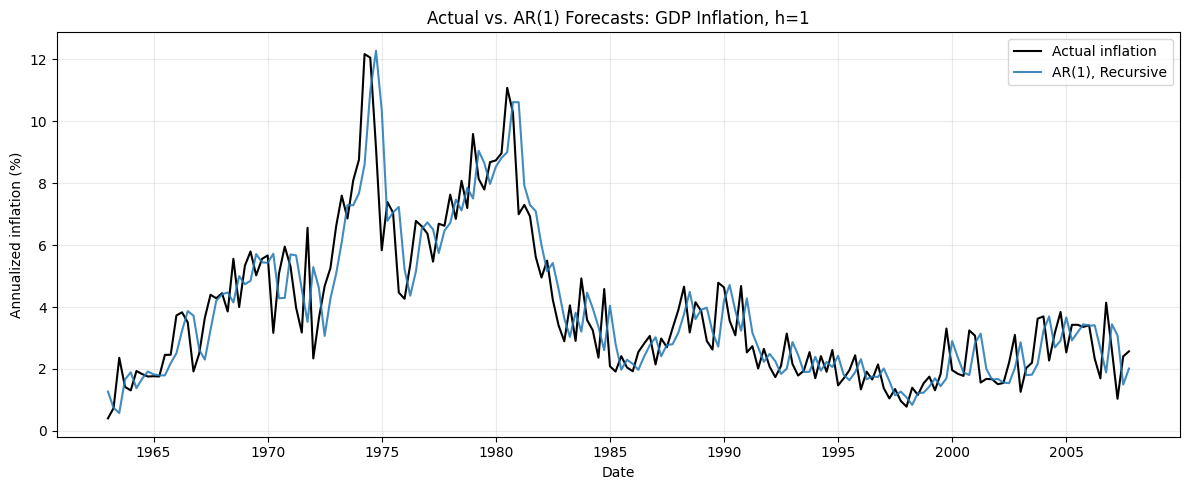

In [44]:
import matplotlib.pyplot as plt

measure = "p_gdp"
h = 1

result = ar1_recursive[(measure, h)].dropna()

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(
    result.index, result["actual"],
    label="Actual inflation", color="black", linewidth=1.5
)
ax.plot(
    result.index, result["forecast"],
    label="AR(1), Recursive", alpha=0.85
)

ax.set_title("Actual vs. AR(1) Forecasts: GDP Inflation, h=1")
ax.set_xlabel("Date")
ax.set_ylabel("Annualized inflation (%)")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

The figure compares actual quarterly GDP price inflation (annualized, black) with one-quarter-ahead forecasts from the recursive AR(1) model (blue). At each date, the model is re-estimated using only data available at that point and forecasts inflation over the next quarter. The forecasts track the broad path of inflation closely: the rise through the 1960s and 1970s, the two peaks near 12% (1974) and 11% (1980), the decline through the Volcker disinflation of the early 1980s, and the low, stable inflation of roughly 1.5 to 4% during the Great Moderation.
However, the forecast mostly trails actual inflation by about one quarter. This is because the model is built to forecast the change in inflation, but changes in quarterly inflation are largely unpredictable noise, so the forecast stays very close to current inflation. In effect, the model is saying “next quarter’s inflation will be about what it is today, adjusted slightly.” The result is that it follows trends well but misses turning points, such as the sharp spikes and drops around 1974 to 1975 and 1980 to 1981, where it only catches up after the move has happened.


## 5. Examining Forecast Errors

Forecast errors are calculated as actual inflation minus forecasted inflation. Positive errors indicate that the model underestimated inflation, while negative errors indicate that it overestimated inflation. The horizontal zero line represents a perfectly accurate forecast.

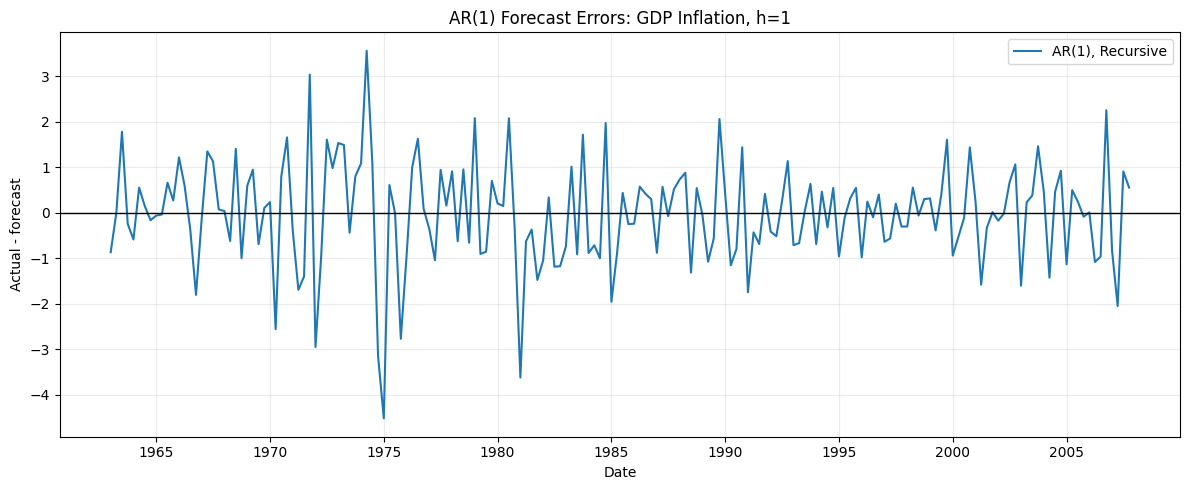

In [45]:
errors = result["actual"] - result["forecast"]

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(errors.index, errors, label="AR(1), Recursive")
ax.axhline(0, color="black", linewidth=1)

ax.set_title("AR(1) Forecast Errors: GDP Inflation, h=1")
ax.set_xlabel("Date")
ax.set_ylabel("Actual - forecast")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 6. Recursive AR(4) Forecasts

This section estimates recursive AR(4) forecasting models for each of the five inflation measures over forecast horizons of one to twelve quarters. The model regresses the constructed inflation target (`yh`) on a constant and the current change in inflation and its first three lags.

At each forecast origin, the model is re-estimated using an expanding sample of historical observations, requiring at least 40 complete observations. The estimated coefficients generate a forecast of the target, which is adjusted for the current-inflation component to obtain the forecast of future annualized inflation. Actual outcomes and forecasts are stored in `ar4_recursive` for subsequent evaluation.

In [46]:

# Forecasting parameters
ar4_columns = [f"ddp_lag{i}" for i in range(4)]

ar4_recursive = {}

for measure in inflation_measures:
    sample = forecast_data[measure]
    lag_columns = [f"ddp_lag{i}" for i in range(narmax_ddp)]

    for h in range(1, hmax + 1):

        # Construct the forecast target and actual future inflation
        future_log_change = sample["p"].shift(-h) - sample["p"]

        yh = (400 / h) * (
            future_log_change - h * sample["dp"]
        )
        yh1 = (400 / h) * future_log_change
        yh2 = (400 / h) * (-h * sample["dp"])

        # Combine the target with all six lag columns.
        # Missing rows are removed, matching GAUSS packr().
        training_data = pd.concat(
            [yh.rename("yh"), sample[lag_columns]], axis=1
        )

        # ---------------------------------
        # AR(4): Recursive estimation
        # ---------------------------------
        forecasts = np.full(len(sample), np.nan)

        for t in range(h + 1, len(sample) + 1):
            train_end = t - h

            training = (
                training_data.iloc[:train_end]
                .dropna()
            )

            if len(training) < npmin:
                continue

            X_train = np.column_stack([
                np.ones(len(training)),
                training[ar4_columns].to_numpy()
            ])
            y_train = training["yh"].to_numpy()

            beta = np.linalg.lstsq(
                X_train, y_train, rcond=None
            )[0]

            current_lags = (
                sample[ar4_columns].iloc[t - 1].to_numpy()
            )

            if np.isnan(current_lags).any():
                continue

            X_current = np.concatenate(([1.0], current_lags))
            predicted_yh = X_current @ beta

            forecasts[t - 1] = (
                predicted_yh - yh2.iloc[t - 1]
            )

        ar4_recursive[(measure, h)] = pd.DataFrame(
            {
                "actual": yh1,
                "forecast": forecasts
            },
            index=sample.index
        )



## 7. Evaluating Recursive AR(4) Forecasts

This section plots actual GDP price inflation against the recursive AR(4) forecasts for the one-quarter-ahead horizon. Comparing the two series shows how closely the model tracks inflation over time and how well it captures changes in the inflation rate.

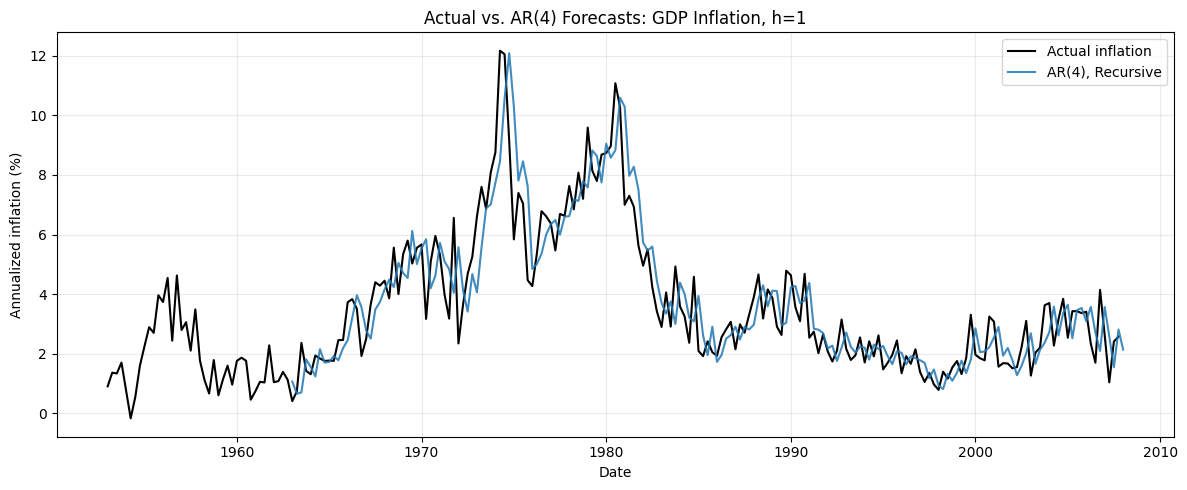

In [47]:
import matplotlib.pyplot as plt

measure = "p_gdp"
h = 1

result = ar4_recursive[(measure, h)]

fig, ax = plt.subplots(figsize=(12, 5))

# Plot actual inflation and recursive AR(4) forecasts.
ax.plot(
    result.index, result["actual"],
    label="Actual inflation",
    color="black",
    linewidth=1.5
)

ax.plot(
    result.index, result["forecast"],
    label="AR(4), Recursive",
    alpha=0.85
)

ax.set_title("Actual vs. AR(4) Forecasts: GDP Inflation, h=1")
ax.set_xlabel("Date")
ax.set_ylabel("Annualized inflation (%)")
ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

The figure compares actual quarterly GDP price inflation (annualized, black) with one-quarter-ahead forecasts from the recursive AR(4) model (blue). The AR(4) model uses the current change in inflation and its three previous lags, and is re-estimated at each date using only data available at that time. Forecasts begin around 1963, once 40 quarters of data are available to estimate the model.
As with the AR(1), the forecasts follow the broad path of inflation well: the build-up through the 1970s, the peaks near 12% (1974) and 11% (1980), the Volcker-era decline, and the low, stable inflation of the Great Moderation. They also again trail actual inflation by about a quarter, catching up with sharp spikes and drops only after they happen (for example, the 1974 peak and the fall in 1975). Adding more lags does not remove this pattern. Visually, the AR(4) forecasts look very similar to the AR(1) forecasts, which suggests that extra lags add little predictive power for quarterly inflation.


## 8. Examining AR(4) Forecast Errors

Forecast errors are calculated as actual inflation minus forecasted inflation. Positive errors indicate that the model underestimated inflation, while negative errors indicate that it overestimated inflation. The zero line represents a perfectly accurate forecast. Plotting these errors over time helps identify periods when the model performs poorly and whether its forecasting accuracy varies across the sample.

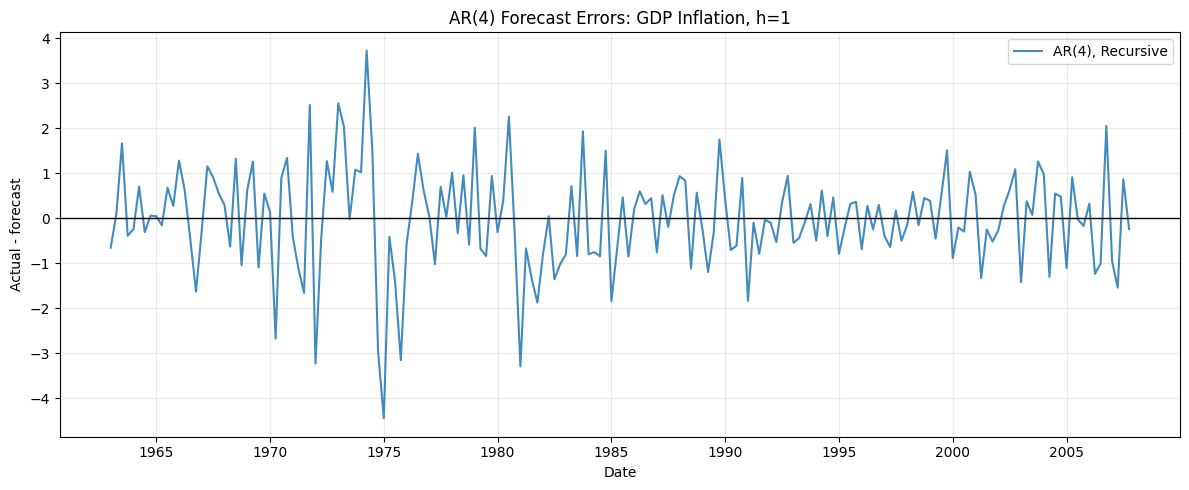

In [48]:
result = ar4_recursive[("p_gdp", 1)].dropna()
errors = result["actual"] - result["forecast"]

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(errors.index, errors, label="AR(4), Recursive", alpha=0.85)

ax.axhline(0, color="black", linewidth=1)
ax.set_title("AR(4) Forecast Errors: GDP Inflation, h=1")
ax.set_xlabel("Date")
ax.set_ylabel("Actual - forecast")
ax.legend()
ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()

## 9. Moving-Average (MA) Forecasts

This section generates forecasts using three moving-average specifications: MA(1) models with fixed coefficients of 0.25 and 0.65, and an MA(2) model with fixed coefficients of 0.487 and 0.158. The models are applied to the change in inflation for each of the five price indexes.

At each forecast origin, the models use the available historical observations, requiring at least 40 usable observations. The MA(1) specifications produce a one-quarter-ahead forecast that is repeated across the forecast horizons, following the implemented GAUSS procedure. The MA(2) model forecasts changes in inflation over twelve quarters and converts them into average annualized inflation forecasts for each horizon.

The code stores actual inflation and forecasted inflation separately for each model, price index, and horizon. Summary statistics are then displayed to inspect the resulting forecasts and their available observations.

In [51]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
import warnings

# Fixed MA(1) and MA(2) coefficients from the GAUSS code
theta25 = 0.25
theta65 = 0.65
theta1 = 0.487
theta2 = 0.158

# Store forecasts for each inflation measure and horizon
ma25_forecasts = {}
ma65_forecasts = {}
ma2_forecasts = {}

for measure in inflation_measures:

    df = forecast_data[measure]
    p = df["p"]
    dp = df["dp"]
    ddp = df["ddp"]

    # Save forecasts for all horizons
    forecast25 = np.full((len(df), hmax), np.nan)
    forecast65 = np.full((len(df), hmax), np.nan)
    forecast2 = np.full((len(df), hmax), np.nan)

    # Begin once at least 40 usable observations are available
    for t in range(npmin - 1, len(df)):

        # Use observations available through quarter t
        history = ddp.iloc[:t + 1].dropna()

        if len(history) < npmin or pd.isna(dp.iloc[t]):
            continue

        # MA(1): theta = 0.25
        model25 = SARIMAX(
            history,
            order=(0, 0, 1),
            trend="n",
            enforce_stationarity=False,
            enforce_invertibility=False
        )

        with model25.fix_params({"ma.L1": -theta25}):
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                result25 = model25.fit(disp=False)

        next_ddp25 = np.asarray(
            result25.get_forecast(steps=1).predicted_mean
        ).reshape(-1)[0]

        next_dp25 = dp.iloc[t] + next_ddp25

        # Repeat the one-quarter-ahead forecast across horizons
        forecast25[t, :] = 400 * next_dp25

        # MA(1): theta = 0.65
        model65 = SARIMAX(
            history,
            order=(0, 0, 1),
            trend="n",
            enforce_stationarity=False,
            enforce_invertibility=False
        )

        with model65.fix_params({"ma.L1": -theta65}):
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                result65 = model65.fit(disp=False)

        next_ddp65 = np.asarray(
            result65.get_forecast(steps=1).predicted_mean
        ).reshape(-1)[0]

        next_dp65 = dp.iloc[t] + next_ddp65

        forecast65[t, :] = 400 * next_dp65

        # MA(2): fixed coefficients
        model2 = SARIMAX(
            history,
            order=(0, 0, 2),
            trend="n",
            enforce_stationarity=False,
            enforce_invertibility=False
        )

        # Fix the MA coefficients; set the innovation variance to 1
        result2 = model2.filter([-theta1, -theta2, 1.0])

        # Forecast future changes in inflation
        future_ddp = np.asarray(
            result2.get_forecast(steps=hmax).predicted_mean
        ).reshape(-1)

        # Convert forecasts of changes into forecasts of inflation
        future_dp = dp.iloc[t] + np.cumsum(future_ddp)

        # Average annualized inflation forecast at each horizon
        forecast2[t, :] = (
            400 * np.cumsum(future_dp) / np.arange(1, hmax + 1)
        )

    # Save actual inflation and forecasts for each horizon
    for h in range(1, hmax + 1):

        actual = 400 / h * (p.shift(-h) - p)

        ma25_forecasts[(measure, h)] = pd.DataFrame({
            "actual": actual,
            "forecast": forecast25[:, h - 1]
        }, index=df.index)

        ma65_forecasts[(measure, h)] = pd.DataFrame({
            "actual": actual,
            "forecast": forecast65[:, h - 1]
        }, index=df.index)

        ma2_forecasts[(measure, h)] = pd.DataFrame({
            "actual": actual,
            "forecast": forecast2[:, h - 1]
        }, index=df.index)


## 10. Comparing Moving-Average Forecasts

This plot compares actual GDP price inflation with one-quarter-ahead forecasts from three moving-average models: MA(1) with θ = 0.25, MA(1) with θ = 0.65, and MA(2). Comparing the series shows how closely each model tracks actual inflation and how their forecasts differ over time.

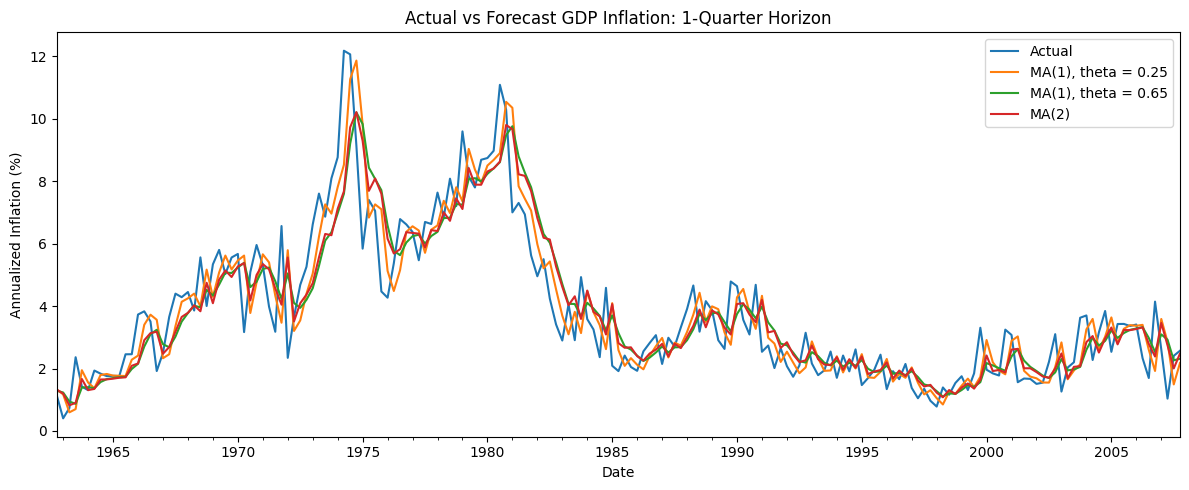

In [49]:
import matplotlib.pyplot as plt

measure = 'p_gdp'
h = 1

comparison = pd.DataFrame({
    'Actual': ma25_forecasts[(measure, h)]['actual'],
    'MA(1), theta = 0.25': ma25_forecasts[(measure, h)]['forecast'],
    'MA(1), theta = 0.65': ma65_forecasts[(measure, h)]['forecast'],
    'MA(2)': ma2_forecasts[(measure, h)]['forecast']
}).dropna()

comparison.plot(figsize=(12, 5))
plt.title('Actual vs Forecast GDP Inflation: 1-Quarter Horizon')
plt.xlabel('Date')
plt.ylabel('Annualized Inflation (%)')
plt.legend()
plt.tight_layout()
plt.show()

## 11. Comparing Moving-Average Forecast Errors

This plot compares the one-quarter-ahead forecast errors for the three moving-average models, calculated as actual inflation minus forecast inflation. Positive errors indicate that a model underpredicted inflation, while negative errors indicate that it overpredicted inflation. The horizontal zero line represents a perfect forecast, allowing the accuracy of the models to be compared over time.

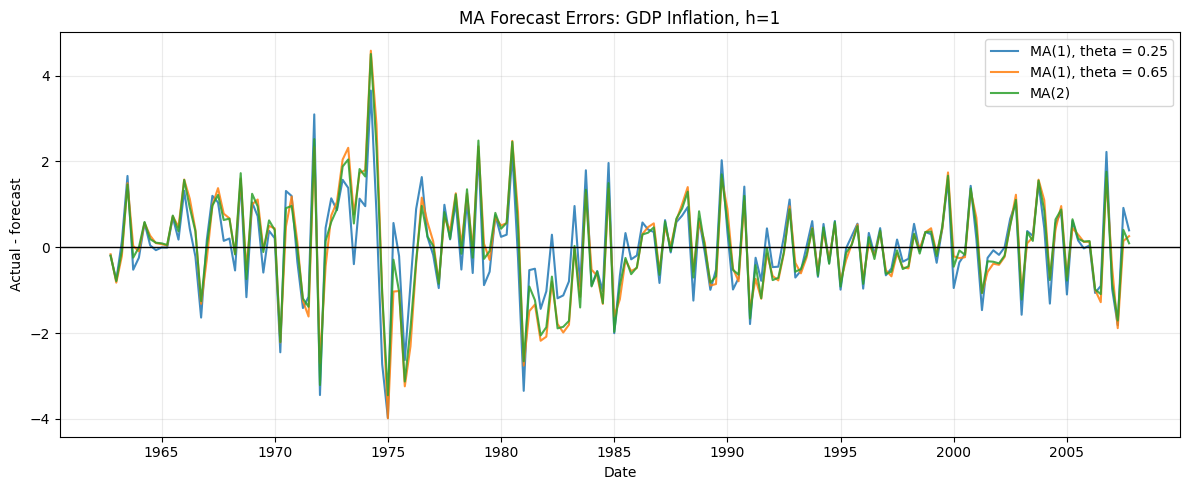

In [50]:
measure = "p_gdp"
h = 1

ma_models = {
    "MA(1), theta = 0.25": ma25_forecasts[(measure, h)],
    "MA(1), theta = 0.65": ma65_forecasts[(measure, h)],
    "MA(2)": ma2_forecasts[(measure, h)]
}

fig, ax = plt.subplots(figsize=(12, 5))

for name, result in ma_models.items():
    comparison = result[["actual", "forecast"]].dropna()
    errors = comparison["actual"] - comparison["forecast"]
    ax.plot(errors.index, errors, label=name, alpha=0.85)

ax.axhline(0, color="black", linewidth=1)
ax.set_title("MA Forecast Errors: GDP Inflation, h=1")
ax.set_xlabel("Date")
ax.set_ylabel("Actual - forecast")
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()